# Sleep Regularity → Depression Risk (v2: leakage-corrected)

**Dataset:** StudentLife (Dartmouth, spring 2013) · 38 students with a post-term PHQ-9 (7 with PHQ-9 ≥ 10)

**Original notebook:** `sleep_regularity_v1_original_leaky.ipynb` (kept unchanged for comparison)

## Summary

| | v1 (original) | v2 (this notebook) |
|---|---|---|
| Evaluation | Random 80/20 split over overlapping 7-day windows | 5×5-fold cross-validation **over students**, scored per student |
| Reported score | Weighted F1 0.78 (RF), 0.82 (LSTM) | AUROC 0.68 (RF), 0.57 (LSTM), 0.49 (logistic) |
| Same RF, same data | AUROC **0.93** | AUROC **0.68** |
| Better than chance? | Not tested | **No.** Best permutation p = 0.097 |
| Conclusion | "Innovation validated" | No evidence that sleep regularity predicts depression in this cohort |

## What was wrong in v1
1. **Subject leakage:** windows from the same student landed in both train and test (38/38 test students had been seen in training).
2. **Duplicated days:** pre- and post-term PHQ-9 were both kept, doubling every row.
3. **Mislabelled "SRI":** the metric wasn't the published Sleep Regularity Index, and it broke on missing nights (48-hour jumps).
4. **Time zone:** UTC treated as local time. **Missing data:** filled with 0.

## Key findings
- **Sleep regularity (SRI):** r = 0.04 with PHQ-9, no association.
- **Mean sleep duration:** r = −0.38, the only notable signal (shorter sleep, higher PHQ-9).
- **PHQ-9 ≥ 5 sensitivity check:** AUROC 0.64, p = 0.226, not significant.
- **Limitation:** 38 students can only detect correlations of r ≥ 0.44. A real but smaller effect can't be ruled out.

## How to run
Runtime → Run all (about 10 minutes on CPU, including permutation tests). Results are saved to `/content/results_v2/` and downloaded as a zip.


In [ ]:
# =====================================================================
# SETUP: installs, imports, and ALL settings in one place
# (v1 problem: settings scattered, no seeds -> results not reproducible)
# =====================================================================
!pip install -q kagglehub

import os, glob, re, copy, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.model_selection import StratifiedKFold, GroupShuffleSplit, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score, balanced_accuracy_score, f1_score, recall_score

warnings.filterwarnings("ignore", category=FutureWarning)

# ---- Experiment settings (change here, nowhere else) ----
SEED           = 42
TZ             = "America/New_York"   # Dartmouth local time; raw timestamps are UTC
SURVEY_WAVE    = "post"               # PHQ-9 taken at END of term = aligned with sensing period
PHQ_THRESHOLD  = 10                   # >=10 = moderate depression (standard screening cut-off)
SLEEP_MIN_H, SLEEP_MAX_H = 3, 14      # a phone-lock episode of 3-14 h is treated as sleep
EPOCH_MIN      = 15                   # resolution (minutes) for the Sleep Regularity Index
WINDOW_DAYS    = 7                    # LSTM sequence length (calendar days)
MIN_VALID_DAYS = 4                    # a window needs >=4 nights with detected sleep
N_SPLITS, N_REPEATS = 5, 5            # 5-fold CV over USERS, repeated 5 times

def set_seed(seed=SEED):
    """Seed every random generator so reruns give identical numbers."""
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

set_seed()
print("Setup done | torch", torch.__version__, "| pandas", pd.__version__)

Setup done | torch 2.11.0+cu130 | pandas 2.2.3


In [ ]:
# =====================================================================
# DATA: download StudentLife from Kaggle (as Dartmouth server times out)
# =====================================================================
import kagglehub

path = kagglehub.dataset_download("dartweichen/student-life")

# Find the dataset root = the folder that contains survey/PHQ-9.csv
phq_file = glob.glob(f"{path}/**/survey/PHQ-9.csv", recursive=True)
assert phq_file, "PHQ-9.csv not found - check the download"
BASE_DIR = os.path.dirname(os.path.dirname(phq_file[0]))
print("BASE_DIR =", BASE_DIR)

for sub in ["sensing/phonelock", "sensing/conversation", "app_usage", "survey"]:
    print(f"  {sub:22s} {len(os.listdir(os.path.join(BASE_DIR, sub)))} files")

100%|██████████| 390M/390M [00:02<00:00, 177MB/s]

Extracting files...


BASE_DIR = /root/.cache/kagglehub/datasets/dartweichen/student-life/versions/1/dataset
  sensing/phonelock      49 files
  sensing/conversation   49 files
  app_usage              49 files
  survey                 8 files


In [ ]:
# =====================================================================
# LOAD RAW SENSOR FILES
# v1 problem: `except: continue` silently dropped broken files.
# v2: every failure is printed and counted.
# =====================================================================
def read_per_user(pattern, required_cols, source):
    """Read one CSV per student, attach uid, report any file that fails."""
    frames, failed = [], []
    for f in sorted(glob.glob(os.path.join(BASE_DIR, pattern))):
        try:
            uid = re.search(r"_(u\d+)\.csv$", f).group(1)      # 'phonelock_u07.csv' -> 'u07'
            df = pd.read_csv(f)
            df.columns = df.columns.str.strip()                # fixes ' end_timestamp' (leading space)
            missing = set(required_cols) - set(df.columns)
            if missing:
                raise KeyError(f"missing columns {sorted(missing)}")
            df = df[required_cols].copy()
            df["uid"] = uid
            frames.append(df)
        except Exception as e:
            failed.append((os.path.basename(f), f"{type(e).__name__}: {e}"))
    print(f"{source:13s}: loaded {len(frames)} files, failed {len(failed)}")
    for name, err in failed:
        print(f"   ⚠ skipped {name} -> {err}")
    return pd.concat(frames, ignore_index=True)

phonelock = read_per_user("sensing/phonelock/phonelock_*.csv", ["start", "end"], "phonelock")
apps      = read_per_user("app_usage/running_app_*.csv", ["timestamp"], "app_usage")
conv      = read_per_user("sensing/conversation/conversation_*.csv",
                          ["start_timestamp", "end_timestamp"], "conversation")

phonelock    : loaded 49 files, failed 0
app_usage    : loaded 49 files, failed 0
conversation : loaded 49 files, failed 0


In [ ]:
# =====================================================================
# STEP 1: LABELS (one PHQ-9 label per student)
# v1 problems: kept pre AND post surveys (every day duplicated in the merge),
#              scored unanswered items as 0, threshold 5 (mild).
# =====================================================================
def process_ground_truth(base_dir, wave=SURVEY_WAVE, threshold=PHQ_THRESHOLD, max_missing=1):
    phq = pd.read_csv(os.path.join(base_dir, "survey/PHQ-9.csv"))
    phq.columns = phq.columns.str.strip()

    # FIX 1: keep ONE survey wave
    phq = phq[phq["type"].str.strip().str.lower() == wave].copy()

    # Score the 9 items (columns 2..10); column 11 is the 'difficulty' question, not scored
    score_map = {"not at all": 0, "several days": 1,
                 "more than half the days": 2, "nearly every day": 3}
    q_cols = phq.columns[2:11]
    items = phq[q_cols].apply(lambda s: s.astype(str).str.strip().str.lower().map(score_map))

    # FIX 2: unanswered != 0. Drop if >1 missing, prorate if exactly 1 missing.
    keep = items.isna().sum(axis=1) <= max_missing
    phq = phq[keep].copy()
    phq["total_score"] = (items[keep].mean(axis=1) * 9).round(1)

    # FIX 3: guarantee one row per student
    phq = phq.drop_duplicates("uid", keep="last")
    phq["label"] = (phq["total_score"] >= threshold).astype(int)
    return phq[["uid", "total_score", "label"]].reset_index(drop=True)

labels = process_ground_truth(BASE_DIR)
assert labels["uid"].is_unique
print(f"Labelled students: {len(labels)} | positive (PHQ-9 >= {PHQ_THRESHOLD}): {labels['label'].sum()}")

Labelled students: 38 | positive (PHQ-9 >= 10): 7


In [ ]:
# =====================================================================
# STEPS 3 & 4: SLEEP FEATURES
# v1 problems: (a) UTC used as local time -> dates/midpoints shifted 4-5 h
#              (b) midpoint kept as raw Unix timestamp; differencing it across a
#                  MISSING day gave 48 h "irregularity"
#              (c) the "SRI" was a rolling std of those differences, not the real SRI
# v2: local time, midpoint as clock time, full calendar, real SRI (Phillips et al. 2017)
# =====================================================================
def to_local(epoch_s):
    """UTC epoch seconds -> naive local (Dartmouth) wall-clock datetime."""
    return pd.to_datetime(epoch_s, unit="s", utc=True).dt.tz_convert(TZ).dt.tz_localize(None)

def hours_since_noon(ts):
    """Clock time as hours after 12:00 (midnight -> 12, 03:00 -> 15). Avoids the midnight wrap."""
    return ((ts.dt.hour + ts.dt.minute / 60) - 12) % 24

# 1) One main sleep episode per night ------------------------------------------
lock = phonelock.dropna().copy()
lock["duration_h"] = (lock["end"] - lock["start"]) / 3600
lock = lock[lock["duration_h"].between(SLEEP_MIN_H, SLEEP_MAX_H)]
lock["onset"]  = to_local(lock["start"])                                 # FIX (a)
lock["offset"] = to_local(lock["end"])
lock["date"]   = (lock["onset"] - pd.Timedelta(hours=12)).dt.normalize()  # noon-to-noon night
episodes = lock.loc[lock.groupby(["uid", "date"])["duration_h"].idxmax()].sort_values(["uid", "date"])

# 2) Daily table on a COMPLETE calendar (missing nights become explicit NaN) ----
def sri_agreement(ep, calendar):
    """Per night: share of 15-min epochs whose sleep/wake state matches 24 h earlier.
    Averaging these and rescaling to [-100, 100] gives the Sleep Regularity Index."""
    per_day = 24 * 60 // EPOCH_MIN
    origin = calendar[0] + pd.Timedelta(hours=12)
    timeline = np.zeros((len(calendar) + 1) * per_day, dtype=np.int8)
    for on, off in zip(ep["onset"], ep["offset"]):
        a = int((on - origin) / pd.Timedelta(minutes=EPOCH_MIN))
        b = int(np.ceil((off - origin) / pd.Timedelta(minutes=EPOCH_MIN)))
        timeline[max(a, 0):max(b, 0)] = 1                                 # 1 = asleep
    grid = timeline[:len(calendar) * per_day].reshape(len(calendar), per_day).astype(float)
    valid = calendar.isin(ep["date"])
    grid[~valid] = np.nan                                                 # unknown, not "awake"
    agree = np.full(len(calendar), np.nan)
    both = valid[1:] & valid[:-1]                                         # only compare 2 observed nights
    agree[1:][both] = (grid[1:][both] == grid[:-1][both]).mean(axis=1)
    return agree

days = []
for uid, ep in episodes.groupby("uid"):
    calendar = pd.date_range(ep["date"].min(), ep["date"].max(), freq="D")
    d = pd.DataFrame({"uid": uid, "date": calendar})
    ep = ep.assign(
        midpoint_h=hours_since_noon(ep["onset"] + (ep["offset"] - ep["onset"]) / 2),  # FIX (b)
        onset_h=hours_since_noon(ep["onset"]),
    )
    d = d.merge(ep[["date", "duration_h", "midpoint_h", "onset_h"]], on="date", how="left")
    d["sleep_valid"] = d["duration_h"].notna()
    d["sri_agree"] = sri_agreement(ep, calendar)                                       # FIX (c)
    days.append(d)
sleep_daily = pd.concat(days, ignore_index=True)

def sri(agree):
    """Sleep Regularity Index: 100 = identical schedule every day, 0 = random."""
    a = pd.Series(agree).dropna()
    return 200 * a.mean() - 100 if len(a) else np.nan

print(f"Calendar days: {len(sleep_daily)} | nights with sleep: {sleep_daily['sleep_valid'].sum()} "
      f"({sleep_daily['sleep_valid'].mean():.0%})")
print(sleep_daily.head(8))

Calendar days: 2907 | nights with sleep: 2025 (70%)
   uid       date  duration_h  midpoint_h    onset_h  sleep_valid  sri_agree
0  u00 2013-03-26    4.546667   16.700000  14.433333         True        NaN
1  u00 2013-03-27         NaN         NaN        NaN        False        NaN
2  u00 2013-03-28    3.673889   17.216667  15.383333         True        NaN
3  u00 2013-03-29         NaN         NaN        NaN        False        NaN
4  u00 2013-03-30    7.775833   17.500000  13.616667         True        NaN
5  u00 2013-03-31    4.793611    9.283333   6.883333         True   0.458333
6  u00 2013-04-01    3.609444   23.816667  22.016667         True   0.708333
7  u00 2013-04-02    4.796389   16.583333  14.183333         True   0.635417


In [ ]:
# =====================================================================
# STEP 5: CONTEXT FEATURES (screen use, conversation)
# v1 problems: UTC dates; `fillna(0)` turned "sensor off" into "zero activity".
# v2: local dates; days with no rows stay NaN; flags record that they were missing.
# =====================================================================
apps["date"] = to_local(apps["timestamp"]).dt.normalize()
screen_daily = apps.groupby(["uid", "date"]).size().rename("screen_samples").reset_index()

conv["dur_s"] = conv["end_timestamp"] - conv["start_timestamp"]
conv_ok = conv[(conv["dur_s"] > 0) & (conv["dur_s"] <= 12 * 3600)].copy()   # drop negative/absurd
conv_ok["date"] = to_local(conv_ok["start_timestamp"]).dt.normalize()
conv_daily = (conv_ok.groupby(["uid", "date"])["dur_s"].sum() / 60).rename("conversation_min").reset_index()

print("screen days:", len(screen_daily), "| conversation days:", len(conv_daily))

screen days: 3108 | conversation days: 2700


In [ ]:
# =====================================================================
# STEP 2: VALIDATED MERGE -> one row per (student, day)
# `validate=` makes pandas CRASH if a key repeats - v1's duplication bug can't return silently.
# =====================================================================
for name, df in [("sleep", sleep_daily), ("screen", screen_daily), ("conversation", conv_daily)]:
    assert not df.duplicated(["uid", "date"]).any(), f"{name} has duplicate (uid, date)"

daily = (sleep_daily
         .merge(screen_daily, on=["uid", "date"], how="left", validate="one_to_one")
         .merge(conv_daily,   on=["uid", "date"], how="left", validate="one_to_one"))

# Missingness flags instead of fillna(0)
daily["screen_missing"]       = daily["screen_samples"].isna()
daily["conversation_missing"] = daily["conversation_min"].isna()
daily["screen_log"]       = np.log1p(daily["screen_samples"])     # log: counts are heavy-tailed
daily["conversation_log"] = np.log1p(daily["conversation_min"])

# Keep only students who have BOTH sensing data and a label
n_sensing = daily["uid"].nunique()
daily = daily[daily["uid"].isin(labels["uid"])].reset_index(drop=True)
labels = labels[labels["uid"].isin(daily["uid"])].reset_index(drop=True)
assert not daily.duplicated(["uid", "date"]).any()

print(f"Students: {n_sensing} with sensing -> {daily['uid'].nunique()} with sensing + label")
print(f"Rows: {len(daily)} | screen missing {daily['screen_missing'].mean():.0%} "
      f"| conversation missing {daily['conversation_missing'].mean():.0%}")

Students: 49 with sensing -> 38 with sensing + label
Rows: 2277 | screen missing 4% | conversation missing 9%


In [ ]:
# =====================================================================
# EDA AT THE RIGHT LEVEL: one row per STUDENT
# v1 problem: correlations over ~3,600 day-rows treated 46 people as 3,600 samples.
# The honest sample size is the number of students.
# =====================================================================
FEATURES = ["duration_mean", "duration_std", "midpoint_mean", "midpoint_std", "onset_std", "sri",
            "screen_log_mean", "conversation_log_mean",
            "sleep_valid_frac", "screen_missing_frac", "conversation_missing_frac"]

def aggregate(block):
    """Summary features for any block of days (a 7-day window or a whole term)."""
    v = block[block["sleep_valid"]]
    return {
        "duration_mean": v["duration_h"].mean(),
        "duration_std":  v["duration_h"].std(ddof=0),
        "midpoint_mean": v["midpoint_h"].mean(),
        "midpoint_std":  v["midpoint_h"].std(ddof=0),
        "onset_std":     v["onset_h"].std(ddof=0),
        "sri":           sri(block["sri_agree"]),
        "screen_log_mean":       block["screen_log"].mean(),
        "conversation_log_mean": block["conversation_log"].mean(),
        "sleep_valid_frac":          block["sleep_valid"].mean(),
        "screen_missing_frac":       block["screen_missing"].mean(),
        "conversation_missing_frac": block["conversation_missing"].mean(),
    }

users = pd.DataFrame([{"uid": u, **aggregate(g)} for u, g in daily.groupby("uid")])
users = users.merge(labels, on="uid")
print(f"{len(users)} students ({users['label'].sum()} positive)")

# Spearman = rank correlation (robust with small n)
corr = users[FEATURES + ["total_score"]].corr(method="spearman")["total_score"].drop("total_score")
print("\nSpearman correlation with PHQ-9 score (n = %d students):" % len(users))
print(corr.sort_values(key=abs, ascending=False).round(2).to_string())
print(f"\nRule of thumb: with n={len(users)}, |r| < {2/np.sqrt(len(users)):.2f} is not significant at p<0.05.")

38 students (7 positive)

Spearman correlation with PHQ-9 score (n = 38 students):
duration_mean               -0.38
screen_missing_frac         -0.28
duration_std                -0.25
sleep_valid_frac             0.22
screen_log_mean              0.19
conversation_missing_frac   -0.17
midpoint_std                -0.14
onset_std                   -0.14
conversation_log_mean       -0.12
midpoint_mean                0.08
sri                          0.04

Rule of thumb: with n=38, |r| < 0.32 is not significant at p<0.05.


In [ ]:
# =====================================================================
# STEP 6: 7-DAY WINDOWS ON THE CALENDAR, each tagged with its student
# v1 problems: windows sliced by ROW (a "7-day" window could span weeks),
#              and the student id was thrown away -> splitting by student impossible.
# =====================================================================
SEQ_FEATURES = ["duration_h", "midpoint_h", "sri_agree", "screen_log", "conversation_log"]
label_of = labels.set_index("uid")["label"]

win_agg, win_seq, win_uid, win_y = [], [], [], []
for uid, g in daily.groupby("uid"):
    g = g.sort_values("date").reset_index(drop=True)          # complete calendar from Cell 5
    for start in range(len(g) - WINDOW_DAYS + 1):
        w = g.iloc[start:start + WINDOW_DAYS]
        if w["sleep_valid"].sum() < MIN_VALID_DAYS:            # too little data -> skip, don't zero-fill
            continue
        win_agg.append(aggregate(w))
        win_seq.append(w[SEQ_FEATURES].to_numpy(np.float32))  # NaN kept; the LSTM masks it
        win_uid.append(uid)
        win_y.append(int(label_of[uid]))

W_AGG = pd.DataFrame(win_agg)[FEATURES].to_numpy(float)
W_SEQ = np.stack(win_seq)
W_UID = np.array(win_uid)
W_Y   = np.array(win_y)
print(f"Windows: {len(W_Y)} from {len(set(W_UID))} students "
      f"(median {pd.Series(W_UID).value_counts().median():.0f} per student) | shape {W_SEQ.shape}")
print("Overlapping windows share 6 of 7 days -> they are NOT independent samples.")

Windows: 1593 from 38 students (median 46 per student) | shape (1593, 7, 5)
Overlapping windows share 6 of 7 days -> they are NOT independent samples.


In [ ]:
# =====================================================================
# MODEL BUILDERS + METRICS (shared by every experiment)
# Imputation/scaling live INSIDE the pipeline, so they are fit on training folds only.
# =====================================================================
def make_majority(seed): return DummyClassifier(strategy="prior")

def make_logistic(seed):
    return Pipeline([("impute", SimpleImputer(strategy="median", keep_empty_features=True)),
                     ("scale", StandardScaler()),
                     ("clf", LogisticRegression(C=0.5, class_weight="balanced", max_iter=2000))])

def make_rf(seed):
    return Pipeline([("impute", SimpleImputer(strategy="median", keep_empty_features=True)),
                     ("clf", RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=5,
                                                    class_weight="balanced_subsample",
                                                    n_jobs=-1, random_state=seed))])

def metrics(y, p, thr=0.5):
    """Screening metrics. AUROC is threshold-free; sensitivity = % of depressed students caught."""
    pred = (np.asarray(p) >= thr).astype(int)
    return {"auroc": roc_auc_score(y, p) if len(set(y)) == 2 else np.nan,
            "bal_acc": balanced_accuracy_score(y, pred),
            "sensitivity": recall_score(y, pred, zero_division=0),
            "specificity": recall_score(1 - np.asarray(y), 1 - pred, zero_division=0),
            "f1_weighted": f1_score(y, pred, average="weighted", zero_division=0)}

In [ ]:
# =====================================================================
# LEAKAGE AUDIT: re-run v1's protocol (random split over windows)
# This reproduces the ORIGINAL mistake on the cleaned data so we can measure it.
# =====================================================================
idx = np.arange(len(W_Y))
tr, te = train_test_split(idx, test_size=0.2, random_state=SEED, stratify=W_Y)
rf = make_rf(SEED).fit(W_AGG[tr], W_Y[tr])
leaky = metrics(W_Y[te], rf.predict_proba(W_AGG[te])[:, 1])

seen = set(W_UID[tr]) & set(W_UID[te])
print("v1 protocol (random window split) — RANDOM FOREST")
print({k: round(v, 3) for k, v in leaky.items()})
print(f"Test students also in training: {len(seen)}/{len(set(W_UID[te]))} "
      f"| test windows from seen students: {np.isin(W_UID[te], list(seen)).mean():.0%}")
print("=> The model is graded on students it has already seen. That is the leak.")

v1 protocol (random window split) — RANDOM FOREST
{'auroc': np.float64(0.931), 'bal_acc': np.float64(0.833), 'sensitivity': 0.843, 'specificity': 0.823, 'f1_weighted': 0.838}
Test students also in training: 38/38 | test windows from seen students: 100%
=> The model is graded on students it has already seen. That is the leak.


In [ ]:
# =====================================================================
# STEP 7: SUBJECT-LEVEL CROSS-VALIDATION (the core fix)
# Folds are made over STUDENTS. All windows of a student are on one side.
# Scoring is per student: average the probabilities of that student's windows.
# =====================================================================
def subject_cv(name, make_model, kind, n_splits=N_SPLITS, n_repeats=N_REPEATS, verbose=True):
    """kind: 'user' = one row per student | 'agg' = window summaries | 'seq' = window sequences."""
    uids, y = users["uid"].to_numpy(), users["label"].to_numpy()
    k = min(n_splits, np.bincount(y).min())                   # can't have more folds than positives
    runs, probs = [], []
    for r in range(n_repeats):
        oof = pd.Series(np.nan, index=uids)
        skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=SEED + r)
        for f, (tr_u, te_u) in enumerate(skf.split(uids, y)):
            train_users, test_users = uids[tr_u], uids[te_u]
            assert not set(train_users) & set(test_users), "LEAK: student in both train and test"
            model = make_model(SEED + 100 * r + f)
            if kind == "user":
                X = users[FEATURES].to_numpy(float)
                model.fit(X[tr_u], y[tr_u])
                oof.iloc[te_u] = model.predict_proba(X[te_u])[:, 1]
            else:
                trm, tem = np.isin(W_UID, train_users), np.isin(W_UID, test_users)
                X = W_SEQ if kind == "seq" else W_AGG
                if kind == "seq":
                    model.fit(X[trm], W_Y[trm], W_UID[trm])   # LSTM needs groups for its inner split
                else:
                    model.fit(X[trm], W_Y[trm])
                p = model.predict_proba(X[tem])[:, 1]
                per_student = pd.Series(p).groupby(W_UID[tem]).mean()   # windows -> student
                oof.loc[per_student.index] = per_student.to_numpy()
        runs.append(metrics(y, oof.to_numpy()))
        probs.append(oof)
    res = pd.DataFrame(runs)
    if verbose:
        print(f"{name:15s} AUROC {res.auroc.mean():.3f} ± {res.auroc.std():.3f} | "
              f"bal.acc {res.bal_acc.mean():.3f} | sens {res.sensitivity.mean():.2f} | spec {res.specificity.mean():.2f}")
    return {"runs": res, "oof": pd.concat(probs, axis=1).mean(axis=1)}

results = {}
results["majority"]      = subject_cv("majority", make_majority, "user")   # floor: predicts prevalence
results["logistic_user"] = subject_cv("logistic_user", make_logistic, "user")
results["random_forest"] = subject_cv("random_forest", make_rf, "agg")

majority        AUROC 0.403 ± 0.000 | bal.acc 0.500 | sens 0.00 | spec 1.00
logistic_user   AUROC 0.493 ± 0.057 | bal.acc 0.523 | sens 0.34 | spec 0.70
random_forest   AUROC 0.680 ± 0.040 | bal.acc 0.486 | sens 0.11 | spec 0.86


lstm            AUROC 0.567 ± 0.071 | bal.acc 0.518 | sens 0.23 | spec 0.81


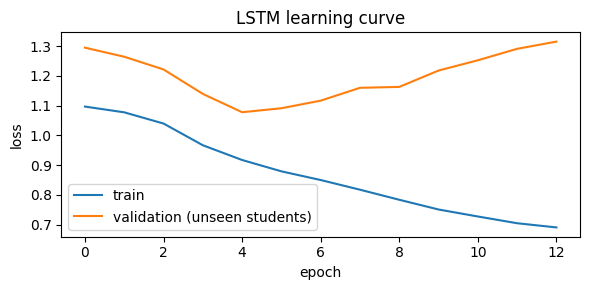

In [ ]:
# =====================================================================
# STEP 9: LSTM done right
# v1 problems: 100 fixed epochs, no validation set, no early stopping, no seed,
#              zeros for missing days, unweighted loss.
# v2: inner validation split BY STUDENT, early stopping, mask channels, class weights.
# =====================================================================
class LSTMNet(nn.Module):
    def __init__(self, n_in, hidden=32, dropout=0.3):
        super().__init__()
        self.lstm = nn.LSTM(n_in, hidden, batch_first=True)
        self.drop = nn.Dropout(dropout)
        self.head = nn.Linear(hidden, 1)
    def forward(self, x):
        _, (h, _) = self.lstm(x)
        return self.head(self.drop(h[-1])).squeeze(-1)

class LSTMClassifier:
    def __init__(self, seed, max_epochs=60, patience=8, lr=1e-3, batch=64):
        self.seed, self.max_epochs, self.patience, self.lr, self.batch = seed, max_epochs, patience, lr, batch
        self.history = []

    def _prep(self, X):
        mask = np.isnan(X).astype(np.float32)                         # 1 = value was missing
        z = np.nan_to_num((X - self.mu) / self.sd, nan=0.0).astype(np.float32)
        return torch.from_numpy(np.concatenate([z, mask], axis=-1))   # model SEES missingness

    def fit(self, X, y, groups):
        set_seed(self.seed)
        # Inner validation split grouped BY STUDENT (no leak inside training either)
        tr, va = next(GroupShuffleSplit(1, test_size=0.2, random_state=self.seed).split(X, y, groups))
        assert not set(groups[tr]) & set(groups[va])
        flat = X[tr].reshape(-1, X.shape[-1])
        self.mu = np.nan_to_num(np.nanmean(flat, 0))                   # stats from TRAIN only
        sd = np.nanstd(flat, 0)
        self.sd = np.where(np.isfinite(sd) & (sd > 1e-8), sd, 1.0)
        Xtr, Xva = self._prep(X[tr]), self._prep(X[va])
        ytr, yva = torch.tensor(y[tr], dtype=torch.float32), torch.tensor(y[va], dtype=torch.float32)

        pos_w = torch.tensor([(len(ytr) - ytr.sum()) / max(ytr.sum(), 1)])   # class imbalance
        loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_w)
        self.net = LSTMNet(Xtr.shape[-1])
        opt = torch.optim.Adam(self.net.parameters(), lr=self.lr, weight_decay=1e-4)

        best, best_state, bad = np.inf, None, 0
        for epoch in range(self.max_epochs):
            self.net.train()
            perm = torch.randperm(len(Xtr))
            for i in range(0, len(perm), self.batch):
                b = perm[i:i + self.batch]
                opt.zero_grad()
                loss_fn(self.net(Xtr[b]), ytr[b]).backward()
                opt.step()
            self.net.eval()
            with torch.no_grad():
                tr_loss = loss_fn(self.net(Xtr), ytr).item()
                va_loss = loss_fn(self.net(Xva), yva).item()
            self.history.append((tr_loss, va_loss))
            if va_loss < best - 1e-4:                                  # early stopping
                best, best_state, bad = va_loss, copy.deepcopy(self.net.state_dict()), 0
            else:
                bad += 1
                if bad >= self.patience:
                    break
        self.net.load_state_dict(best_state)
        return self

    def predict_proba(self, X):
        self.net.eval()
        with torch.no_grad():
            p = torch.sigmoid(self.net(self._prep(X))).numpy()
        return np.column_stack([1 - p, p])

results["lstm"] = subject_cv("lstm", lambda s: LSTMClassifier(s), "seq")

# Learning curves of one fit: validation loss should flatten/rise -> early stopping kicks in
demo = LSTMClassifier(SEED).fit(W_SEQ, W_Y, W_UID)
h = np.array(demo.history)
plt.figure(figsize=(6, 3))
plt.plot(h[:, 0], label="train"); plt.plot(h[:, 1], label="validation (unseen students)")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.title("LSTM learning curve"); plt.legend(); plt.tight_layout()
plt.show()

Subject-level CV (scored per student):
               AUROC  AUROC_std  Balanced acc  Sensitivity  Specificity
majority       0.403      0.000         0.500        0.000        1.000
logistic_user  0.493      0.057         0.523        0.343        0.703
random_forest  0.680      0.040         0.486        0.114        0.858
lstm           0.567      0.071         0.518        0.229        0.806


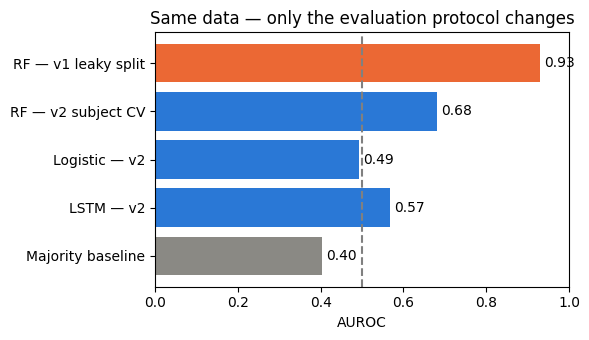

In [ ]:
# =====================================================================
# RESULTS: leaky (v1) vs honest (v2), side by side
# =====================================================================
summary = pd.DataFrame({
    name: {"AUROC": r["runs"].auroc.mean(), "AUROC_std": r["runs"].auroc.std(),
           "Balanced acc": r["runs"].bal_acc.mean(),
           "Sensitivity": r["runs"].sensitivity.mean(), "Specificity": r["runs"].specificity.mean()}
    for name, r in results.items()}).T.round(3)
print("Subject-level CV (scored per student):")
print(summary.to_string())

fig, ax = plt.subplots(figsize=(6, 3.5))
bars = {"RF — v1 leaky split": leaky["auroc"], "RF — v2 subject CV": summary.loc["random_forest", "AUROC"],
        "Logistic — v2": summary.loc["logistic_user", "AUROC"], "LSTM — v2": summary.loc["lstm", "AUROC"],
        "Majority baseline": summary.loc["majority", "AUROC"]}
ax.barh(list(bars), list(bars.values()), color=["#eb6834"] + ["#2a78d6"] * 3 + ["#8a8984"])
ax.axvline(0.5, ls="--", c="gray"); ax.set_xlim(0, 1); ax.set_xlabel("AUROC")
for i, v in enumerate(bars.values()):
    ax.text(v + 0.01, i, f"{v:.2f}", va="center")
ax.invert_yaxis(); ax.set_title("Same data — only the evaluation protocol changes"); plt.tight_layout()
plt.show()


Observed AUROC 0.493 | shuffled mean 0.478 | 95th pct 0.750 | p = 0.471


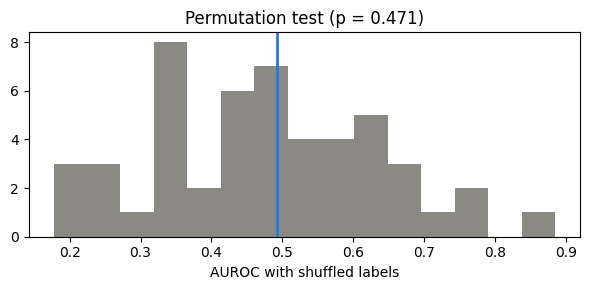

In [ ]:
# =====================================================================
# STEP 10:
# a. IS IT BETTER THAN CHANCE? (permutation test)
# Shuffle the labels across students, rerun the whole CV, repeat.
# If the real AUROC is not above ~95% of shuffled runs, there is no evidence of signal.
# =====================================================================
N_PERM = 50
observed = summary.loc["logistic_user", "AUROC"]
rng = np.random.default_rng(SEED)
true_labels = users["label"].copy()
null = []
for i in range(N_PERM):
    users["label"] = rng.permutation(true_labels.to_numpy())   # break the student-label link
    r = subject_cv("perm", make_logistic, "user", n_repeats=2, verbose=False)
    null.append(r["runs"].auroc.mean())
users["label"] = true_labels                                  # restore real labels!

p_value = (1 + np.sum(np.array(null) >= observed)) / (1 + N_PERM)
print(f"\nObserved AUROC {observed:.3f} | shuffled mean {np.mean(null):.3f} "
      f"| 95th pct {np.percentile(null, 95):.3f} | p = {p_value:.3f}")
plt.figure(figsize=(6, 3))
plt.hist(null, bins=15, color="#8a8984"); plt.axvline(observed, c="#2a78d6", lw=2)
plt.xlabel("AUROC with shuffled labels"); plt.title(f"Permutation test (p = {p_value:.3f})"); plt.tight_layout()
plt.show()

In [ ]:
# =====================================================================
# STEP 10:
# b — PERMUTATION TEST FOR ANY MODEL (RF needs it before we claim 0.68)
# Shuffles labels across STUDENTS and applies the same shuffle to their windows.
# =====================================================================
def perm_test(name, make_model, kind, observed, n_perm=30, n_repeats=2):
    global W_Y
    rng = np.random.default_rng(SEED)
    true_user_labels, true_W_Y = users["label"].copy(), W_Y.copy()
    null = []
    try:
        for i in range(n_perm):
            shuffled = dict(zip(users["uid"], rng.permutation(true_user_labels.to_numpy())))
            users["label"] = users["uid"].map(shuffled)
            W_Y = pd.Series(W_UID).map(shuffled).to_numpy()          # windows follow their student
            null.append(subject_cv(name, make_model, kind, n_repeats=n_repeats, verbose=False)["runs"].auroc.mean())
            print(f"\r  {name}: permutation {i + 1}/{n_perm}", end="")
    finally:
        users["label"], W_Y = true_user_labels, true_W_Y              # ALWAYS restore real labels
    p = (1 + np.sum(np.array(null) >= observed)) / (1 + n_perm)
    print(f"\n{name}: observed {observed:.3f} | null mean {np.mean(null):.3f} "
          f"| null 95th pct {np.percentile(null, 95):.3f} | p = {p:.3f}")
    return p

p_rf = perm_test("random_forest", make_rf, "agg", summary.loc["random_forest", "AUROC"])

  random_forest: permutation 30/30
random_forest: observed 0.680 | null mean 0.495 | null 95th pct 0.713 | p = 0.097


In [ ]:
# =====================================================================
# WHICH FEATURES MATTER? (logistic coefficients, fit per fold)
# Standardised coefficients: sign = direction, size = strength. Std shows stability.
# =====================================================================
coefs = []
X, y = users[FEATURES].to_numpy(float), users["label"].to_numpy()
for r in range(N_REPEATS):
    for tr_u, _ in StratifiedKFold(min(N_SPLITS, y.sum()), shuffle=True, random_state=SEED + r).split(X, y):
        coefs.append(make_logistic(SEED).fit(X[tr_u], y[tr_u]).named_steps["clf"].coef_[0])
coef = pd.DataFrame(coefs, columns=FEATURES)
coef_table = pd.DataFrame({"mean": coef.mean(), "std": coef.std()}).sort_values("mean", key=abs, ascending=False)
print(coef_table.round(3).to_string())
print("\nA feature is only worth discussing if |mean| is clearly larger than std.")

                            mean    std
sleep_valid_frac           0.693  0.174
conversation_log_mean     -0.691  0.199
screen_log_mean            0.484  0.281
duration_mean             -0.473  0.159
sri                       -0.416  0.231
screen_missing_frac       -0.347  0.187
midpoint_std               0.172  0.187
midpoint_mean             -0.158  0.234
duration_std              -0.110  0.148
onset_std                 -0.044  0.142
conversation_missing_frac  0.010  0.383

A feature is only worth discussing if |mean| is clearly larger than std.


In [ ]:
# =====================================================================
# SENSITIVITY ANALYSIS: does the conclusion change at PHQ-9 >= 5 (mild)?
# =====================================================================
saved = users.copy()
lab5 = process_ground_truth(BASE_DIR, threshold=5)[["uid", "label"]]
users = saved.drop(columns="label").merge(lab5, on="uid")
print(f"Threshold 5: {users['label'].sum()}/{len(users)} positive")
res5 = subject_cv("logistic @ PHQ>=5", make_logistic, "user")
p_t5 = perm_test("logistic @ PHQ>=5", make_logistic, "user", res5["runs"].auroc.mean())  # BEFORE restoring
users = saved                                                  # restore main analysis AFTER the test

Threshold 5: 19/38 positive
logistic @ PHQ>=5 AUROC 0.638 ± 0.053 | bal.acc 0.621 | sens 0.59 | spec 0.65
  logistic @ PHQ>=5: permutation 30/30
logistic @ PHQ>=5: observed 0.638 | null mean 0.506 | null 95th pct 0.713 | p = 0.226


In [ ]:
# =====================================================================
# SAVE EVERYTHING for the write-up
# =====================================================================
OUT = "/content/results_v2"
os.makedirs(OUT, exist_ok=True)

# 1) Model performance (subject-level CV, scored per student)
summary.to_csv(f"{OUT}/subject_cv_summary.csv")

# 2) Feature effects (logistic coefficients across folds)
coef_table.to_csv(f"{OUT}/logistic_coefficients.csv")

# 3) One row per student: features + PHQ-9 score + label
users.to_csv(f"{OUT}/user_features.csv", index=False)

# 4) Leakage audit: same model, v1 split vs v2 subject CV
pd.DataFrame([
    {"protocol": "v1 random window split (RF)", **leaky},
    {"protocol": "v2 subject CV (RF)", **results["random_forest"]["runs"].mean().to_dict()},
]).to_csv(f"{OUT}/leaky_vs_subject.csv", index=False)

# 5) All three permutation tests in one table
perm_table = pd.DataFrame([
    {"test": "logistic @ PHQ>=10",      "observed_auroc": observed,                              "p_value": p_value},
    {"test": "random_forest @ PHQ>=10", "observed_auroc": summary.loc["random_forest", "AUROC"], "p_value": p_rf},
    {"test": "logistic @ PHQ>=5",       "observed_auroc": res5["runs"].auroc.mean(),             "p_value": p_t5},
]).round(3)
perm_table.to_csv(f"{OUT}/permutation_tests.csv", index=False)
print(perm_table.to_string(index=False))

# 6) Zip and download (Colab deletes /content when the session ends)
import shutil
from google.colab import files
shutil.make_archive("/content/results_v2", "zip", OUT)
files.download("/content/results_v2.zip")
print("\nSaved to", OUT, "->", sorted(os.listdir(OUT)))

                   test  observed_auroc  p_value
     logistic @ PHQ>=10           0.493    0.471
random_forest @ PHQ>=10           0.680    0.097
      logistic @ PHQ>=5           0.638    0.226


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Saved to /content/results_v2 -> ['leaky_vs_subject.csv', 'logistic_coefficients.csv', 'permutation_tests.csv', 'subject_cv_summary.csv', 'user_features.csv']
